In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar dataset
df = pd.read_csv("EngineFaultDB_Final.csv")

# Variable objetivo
target = "Fault"

# Variables predictoras
features = [col for col in df.columns if col != target]

# Colores para cada clase
colors = {
    0: "blue",
    1: "orange",
    2: "green",
    3: "red"
}

print("Número de variables:", len(features))
print("Clases:", sorted(df[target].unique()))

Número de variables: 14
Clases: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


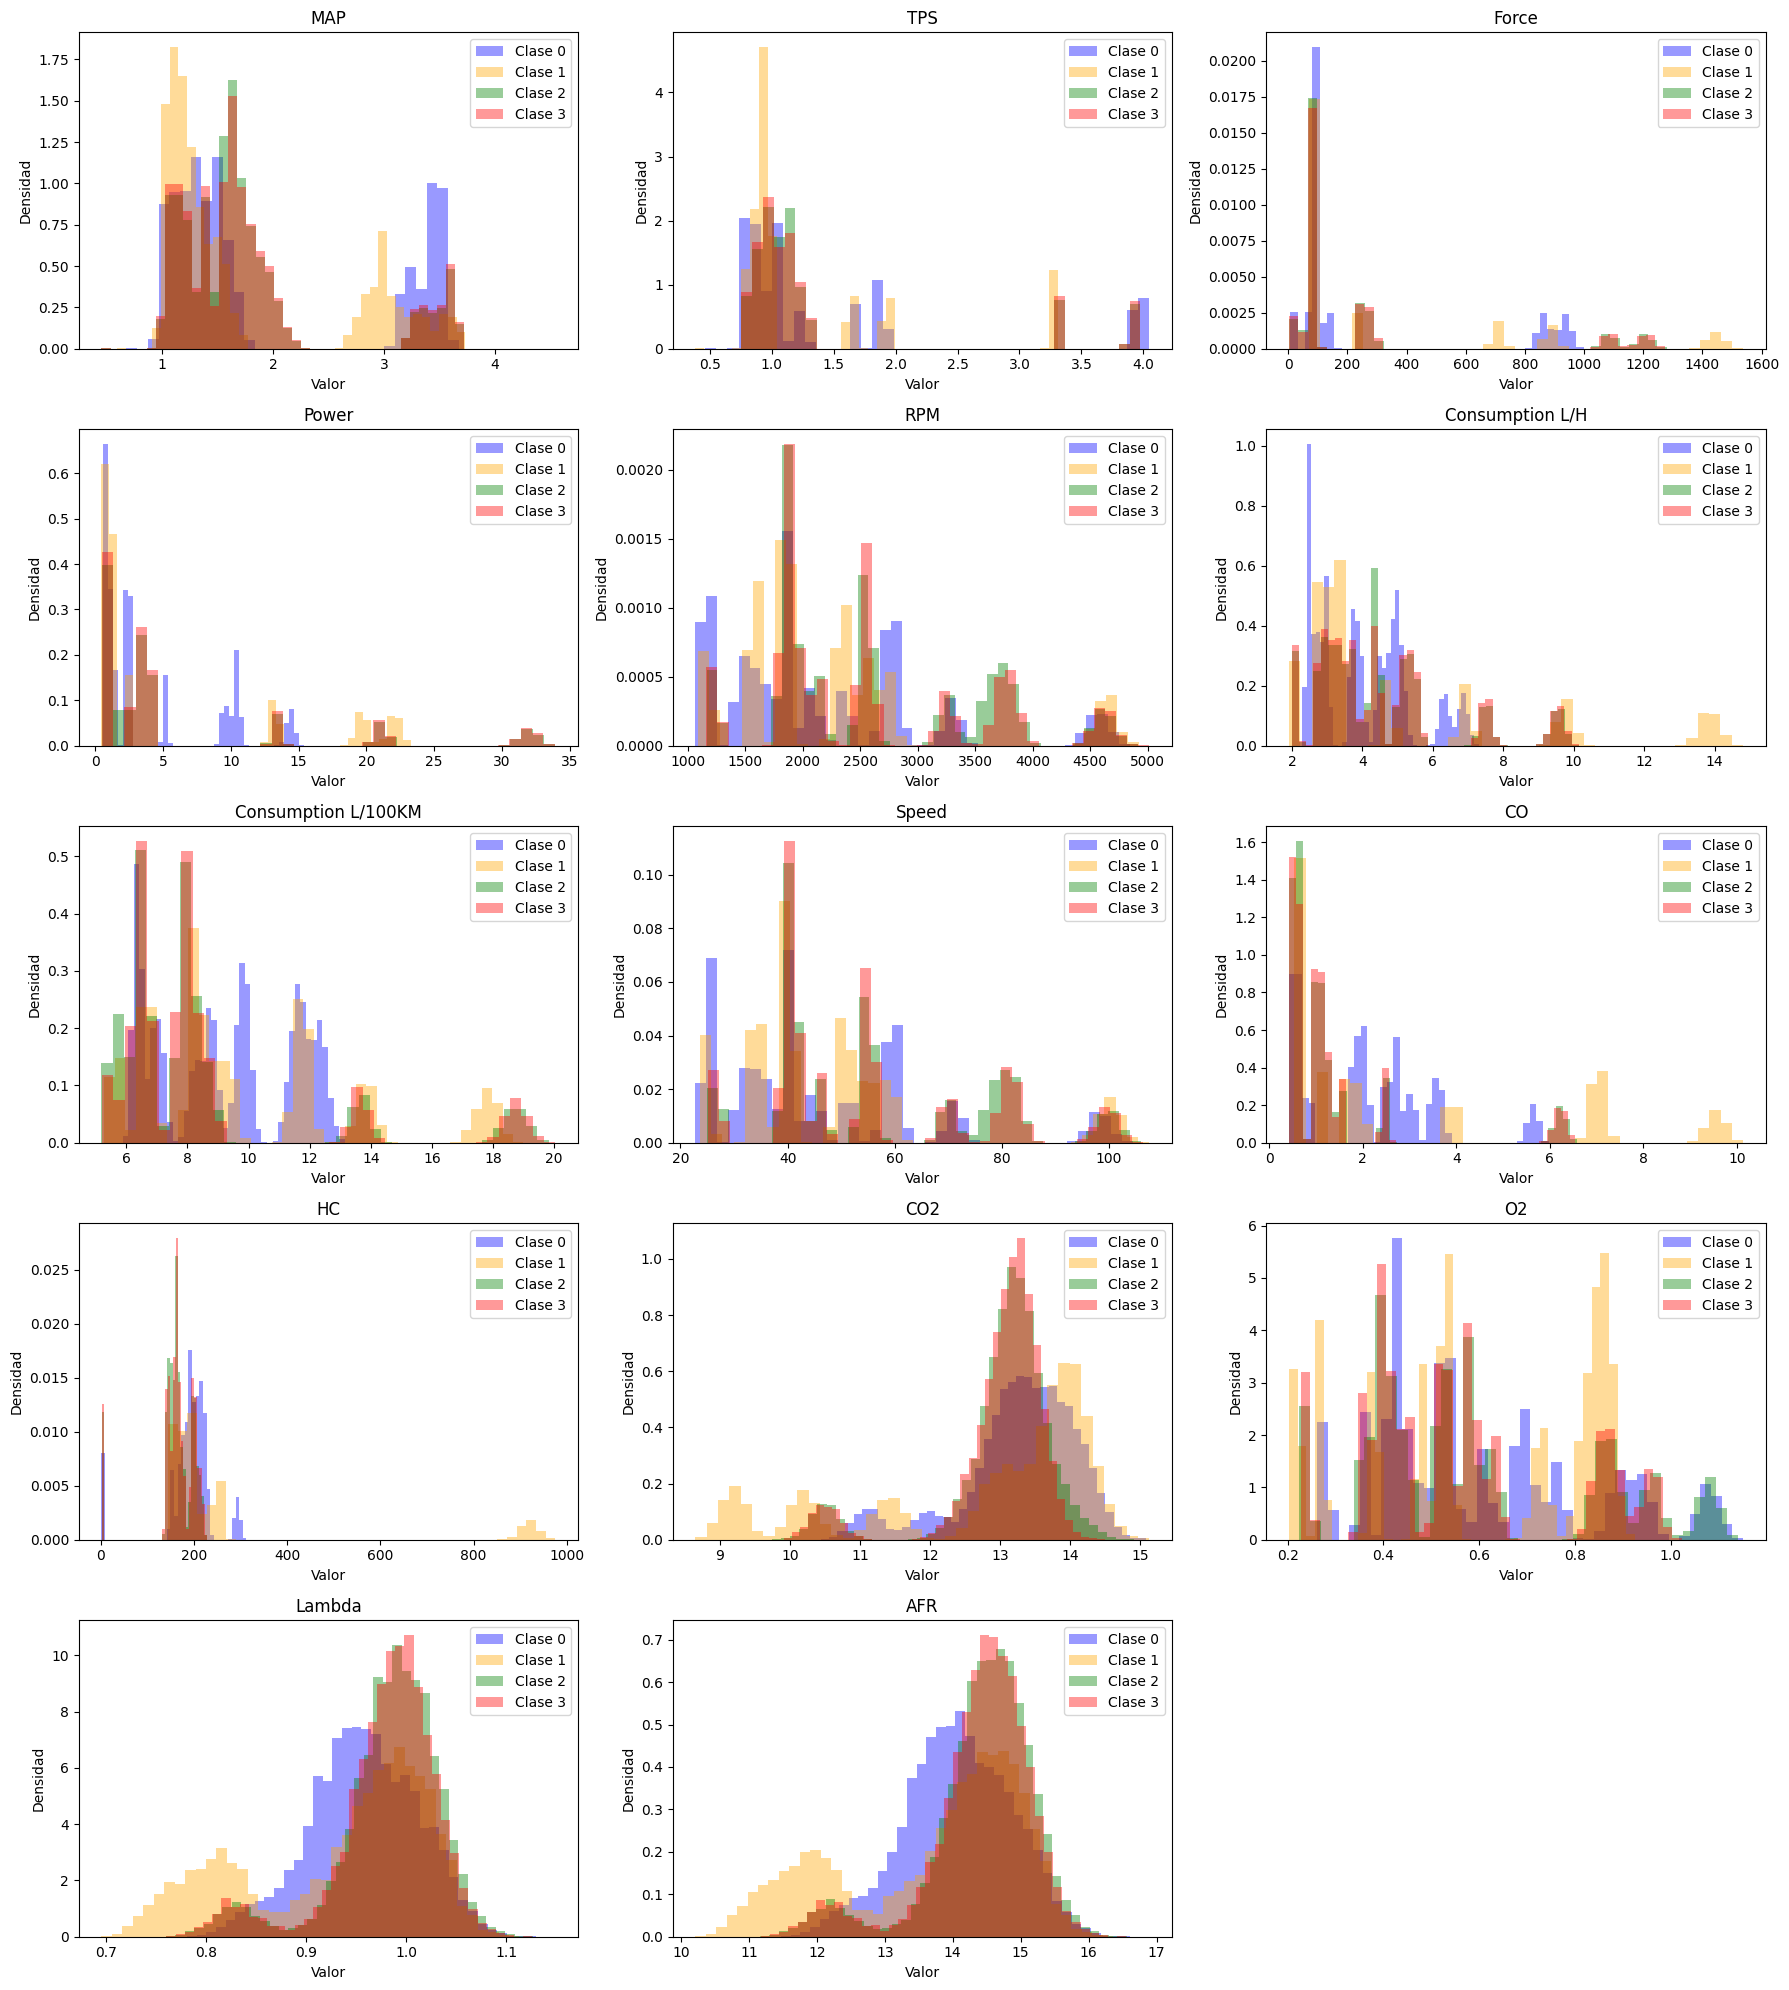

In [2]:
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(features):

    for cls in sorted(df[target].unique()):

        subset = df[df[target] == cls]

        axes[i].hist(
            subset[feature],
            bins=40,
            density=True,
            alpha=0.4,
            color=colors[cls],
            label=f"Clase {cls}"
        )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Densidad")
    axes[i].legend()

# Eliminar gráficos vacíos
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_1616/4007390176.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_1616/4007390176.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_1616/4007390176.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_1616/4007390176.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(
/tmp/ipykernel_1616/4007390176.py:18: MatplotlibDeprecationWarning: The 'lab

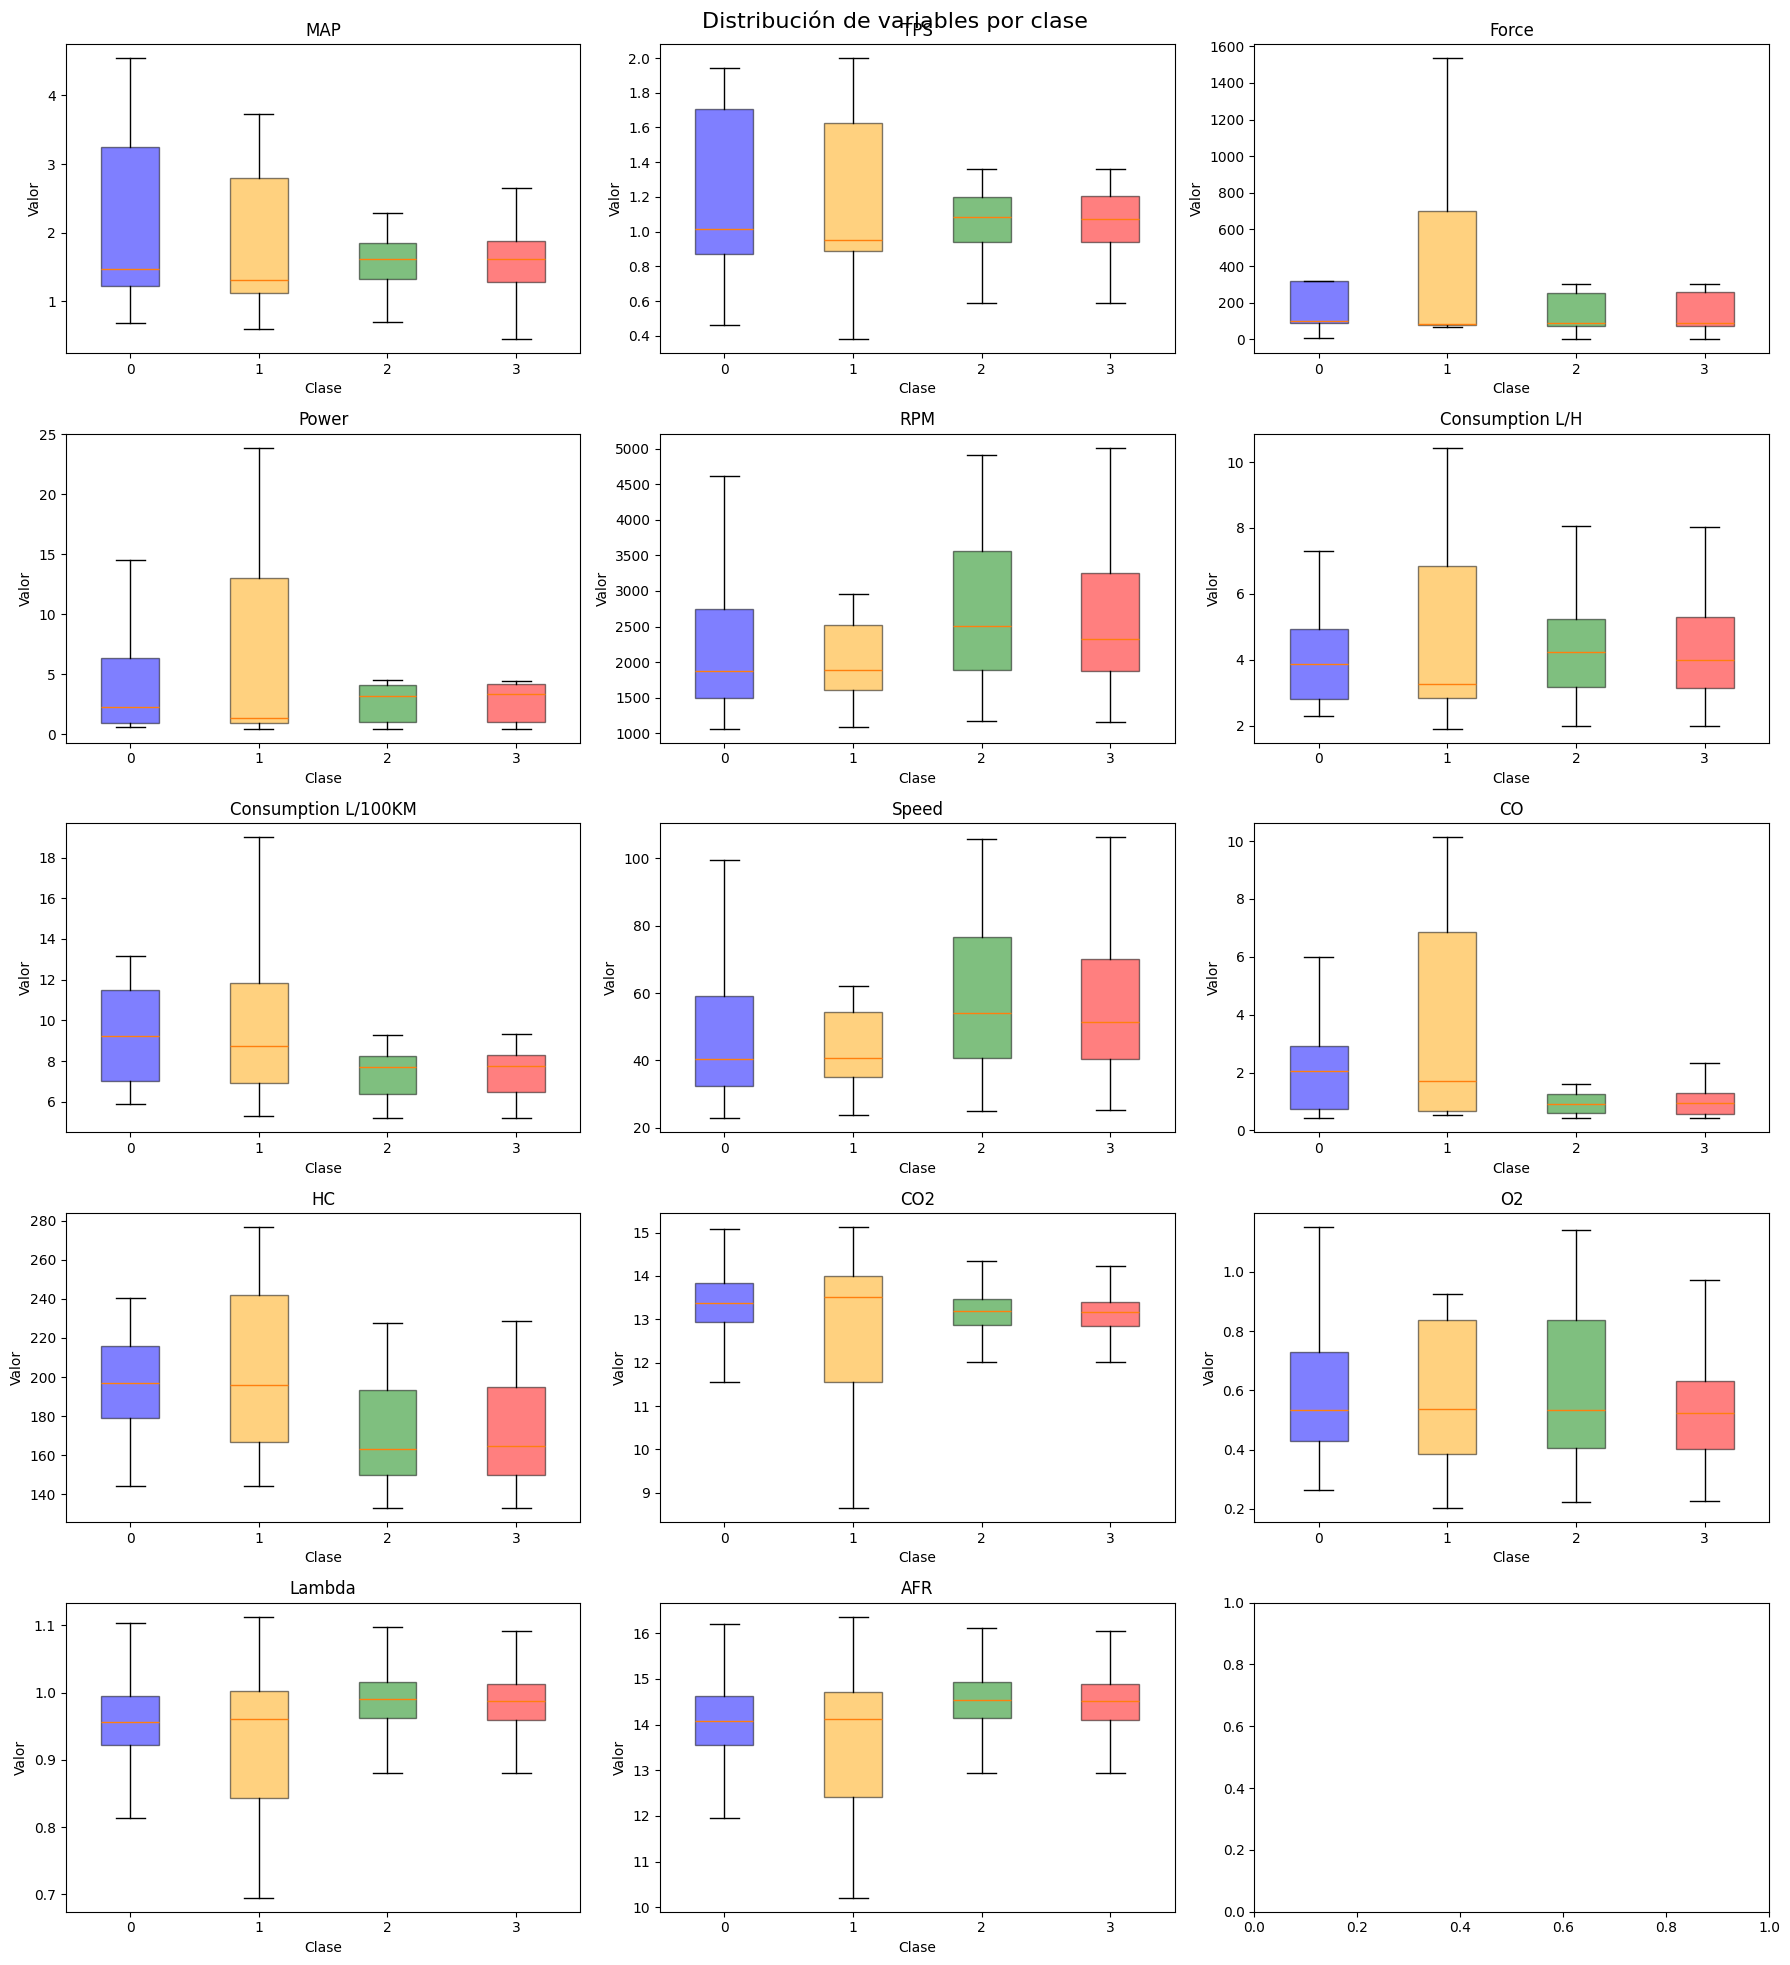

In [3]:
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(features):

    data = [
        df.loc[df[target] == cls, feature]
        for cls in sorted(df[target].unique())
    ]

    bp = axes[i].boxplot(
        data,
        patch_artist=True,
        labels=sorted(df[target].unique()),
        showfliers=False
    )

    for patch, cls in zip(bp["boxes"], sorted(df[target].unique())):
        patch.set_facecolor(colors[cls])
        patch.set_alpha(0.5)

    axes[i].set_title(feature)
    axes[i].set_xlabel("Clase")
    axes[i].set_ylabel("Valor")

fig.suptitle("Distribución de variables por clase", fontsize=16)
plt.tight_layout()
plt.show()

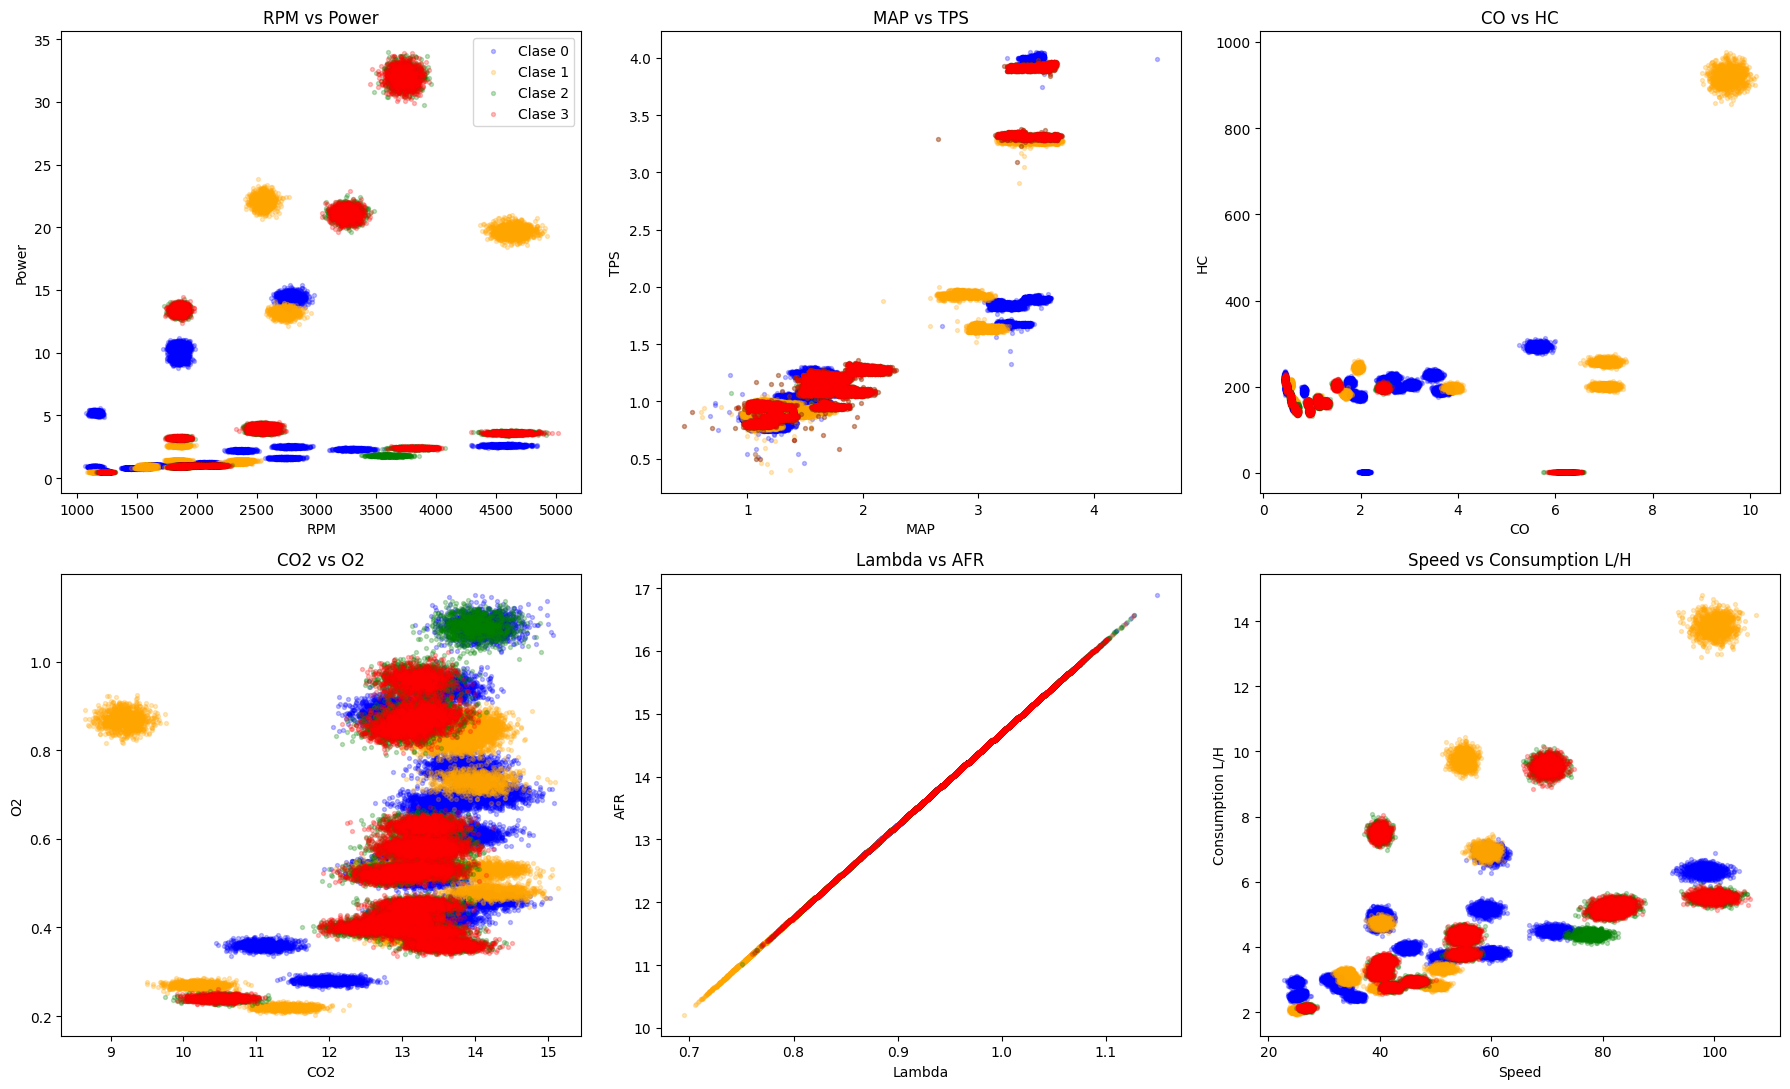

In [4]:
combinations = [
    ("RPM", "Power"),
    ("MAP", "TPS"),
    ("CO", "HC"),
    ("CO2", "O2"),
    ("Lambda", "AFR"),
    ("Speed", "Consumption L/H")
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (x, y) in zip(axes.flatten(), combinations):

    for cls in sorted(df[target].unique()):

        subset = df[df[target] == cls]

        ax.scatter(
            subset[x],
            subset[y],
            color=colors[cls],
            label=f"Clase {cls}",
            alpha=0.25,
            s=8
        )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

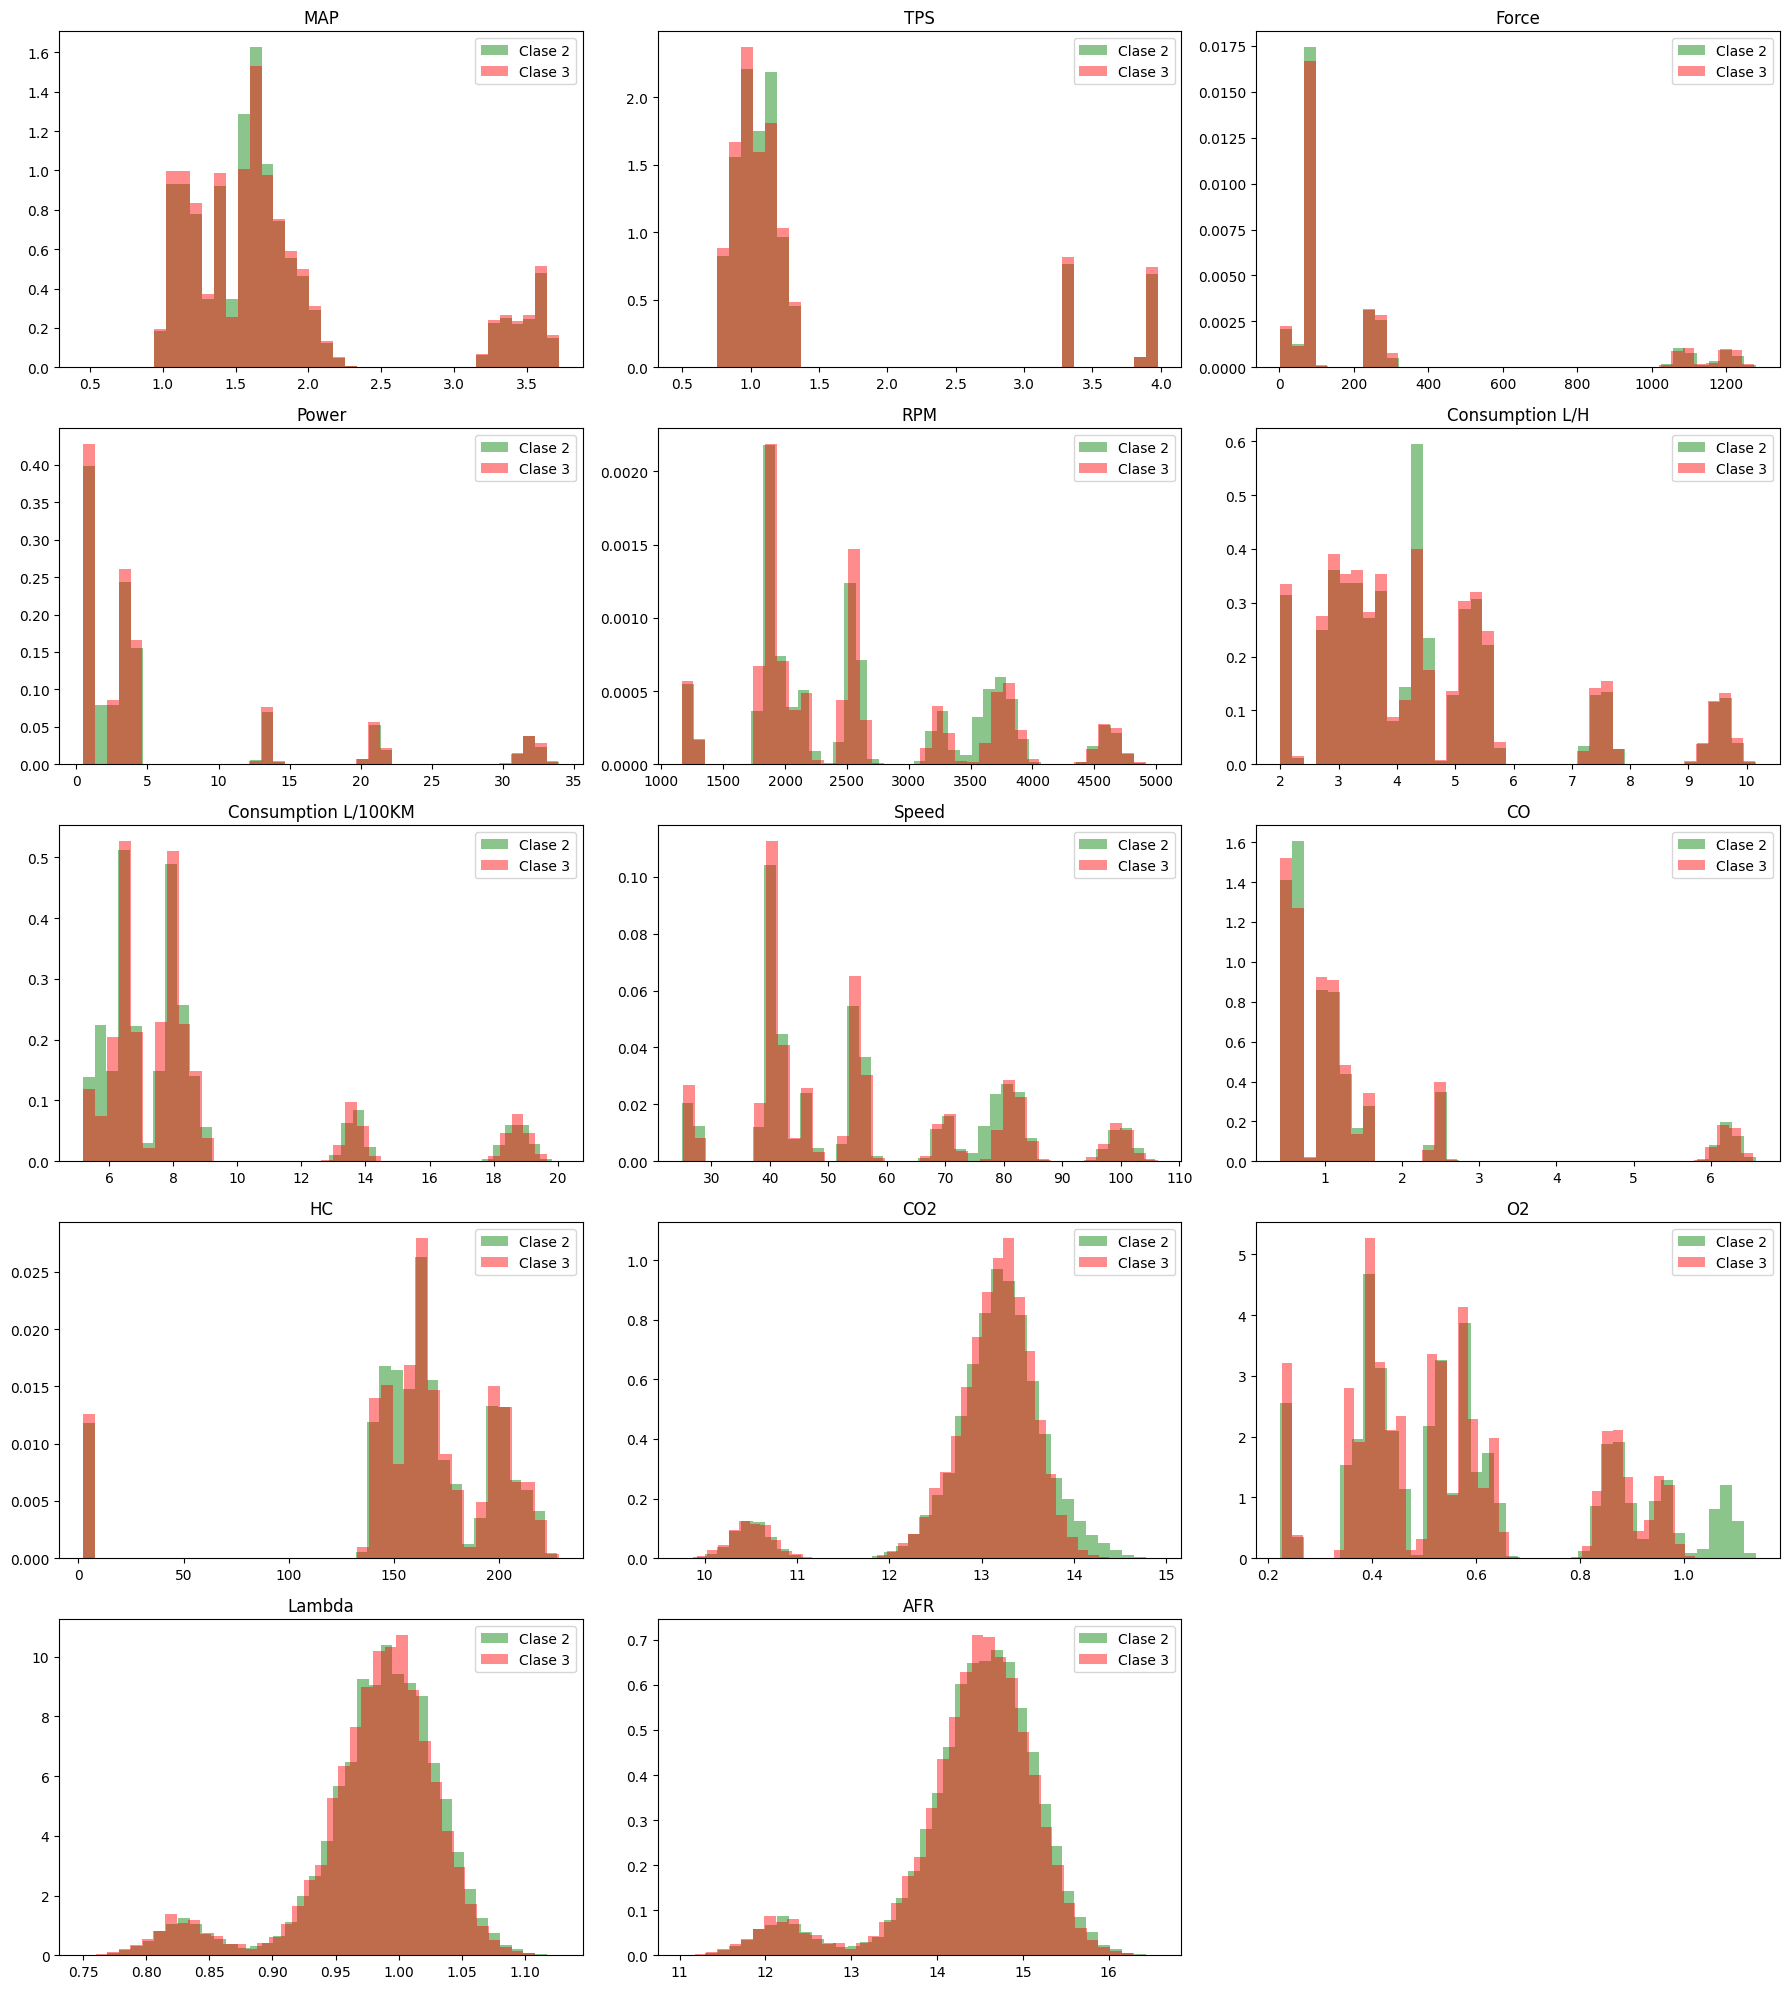

In [5]:
df_23 = df[df["Fault"].isin([2, 3])]

n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(features):

    for cls in [2, 3]:

        subset = df_23[df_23["Fault"] == cls]

        axes[i].hist(
            subset[feature],
            bins=40,
            density=True,
            alpha=0.45,
            color=colors[cls],
            label=f"Clase {cls}"
        )

    axes[i].set_title(feature)
    axes[i].legend()

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()